# Imports

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Exmaple

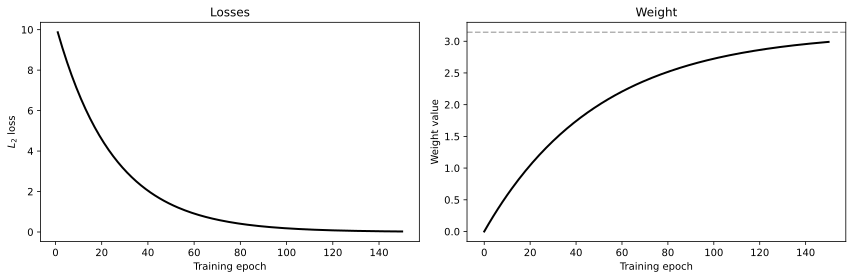

In [ ]:
# initialize weight value
w = torch.tensor([0.], requires_grad = True)

# target value
target = torch.tensor([torch.pi])

# learning rate
lr = .01

# create the optimizers
optimizer = torch.optim.SGD([w], lr = lr)

# number of training iterations
num_iters = 150

# initialize results matrices
all_losses  = np.zeros(num_iters)
all_weights = np.zeros(num_iters + 1)
all_weights[0] = w.item()

# training loop
for i in range(num_iters):

  # train the weight
  optimizer.zero_grad()
  loss = (w-target)**2
  loss.backward()
  optimizer.step()

  # store the loss and update the weight value
  all_losses[i]    = loss.item()
  all_weights[i+1] = w.item()

# visualization
_, axs = plt.subplots(1,2,figsize=(12,4))

# plot the losses and weight values
axs[0].plot(range(1,num_iters+1), all_losses,  'k', linewidth = 2)
axs[1].plot(range(0,num_iters+1), all_weights, 'k', linewidth = 2)

axs[0].set(title = 'Losses', ylabel = '$L_2$ loss', xlabel = 'Training epoch')
axs[1].set(title = 'Weight', ylabel = 'Weight value', xlabel = 'Training epoch')
axs[1].axhline(target, linestyle = '--', color = [.7,.7,.7], label = 'Target')

plt.tight_layout()
plt.show()

# Optimizer Comparison

Adam and AdamW is divided by its standard deviation of gradient therefore values dont increase immediately. SGD powers up only difference between target and weights without division, which causes high increase in values. That's why we will use 0.04 initial value for SGD and 0.1 initial value for Adam and AdamW

In [ ]:
# initialize weight value
wSGD   = torch.tensor([2.], requires_grad = True)
wAdam  = torch.tensor([2.], requires_grad = True)
wAdamW = torch.tensor([2.], requires_grad = True)

# target value
target = torch.tensor([5.])

# learning rates (equal for exercises 1&3; changed in exercise 2)
learningrateSGD = .04
learningrateAdm = .1

# create the optimizers
optimizerSGD   = torch.optim.SGD([wSGD],    lr = learningrateSGD)
optimizerAdam  = torch.optim.AdamW([wAdam], lr = learningrateAdm)
optimizerAdamW = torch.optim.AdamW([wAdamW], lr = learningrateAdm)

# number of training iterations
num_iters = 150

# initialize results matrices
all_losses  = np.zeros((3, num_iters))
all_weights = np.zeros((3, num_iters + 1))
all_weights[:,0] = wSGD.item()

# training loop
for i in range(num_iters):

  # train the SGD weight
  optimizerSGD.zero_grad()
  lossSGD = (wSGD - target)**2
  lossSGD.backward()
  optimizerSGD.step()

  # train with Adam
  optimizerAdam.zero_grad()
  lossAdam = (wAdam - target)**2
  lossAdam.backward()
  optimizerAdam.step()

  # train with AdamW
  optimizerAdamW.zero_grad()
  lossAdamW = (wAdamW - target)**2
  lossAdamW.backward()
  optimizerAdamW.step()

  # store the losses and updated weight value
  all_losses[0,i] = lossSGD.item()
  all_losses[1,i] = lossAdam.item()
  all_losses[2,i] = lossAdamW.item()

  all_weights[0, i+1] = wSGD.item()
  all_weights[1, i+1] = wAdam.item()
  all_weights[2, i+1] = wAdamW.item()

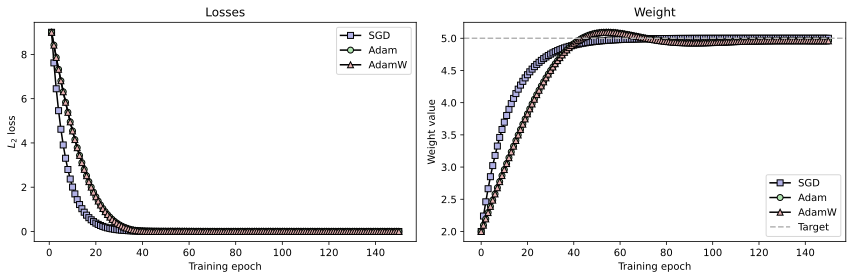

In [ ]:
_, axs = plt.subplots(1, 2, figsize=(12, 4))

optim_labels = ['SGD', 'Adam', 'AdamW']

marker_cols = [
    [.7, .7, .9],
    [.7, .9, .7],
    [.9, .7, .7]
]

shapes = ['s', 'o', '^']

for i in range(3):

    axs[0].plot(
        range(1, num_iters + 1),
        all_losses[i, :],
        color='k',
        marker=shapes[i],
        markerfacecolor=marker_cols[i],
        label=optim_labels[i]
    )

    axs[1].plot(
        range(0, num_iters + 1),
        all_weights[i, :],
        color='k',
        marker=shapes[i],
        markerfacecolor=marker_cols[i],
        label=optim_labels[i]
    )

axs[0].set(
    title='Losses',
    ylabel='$L_2$ loss',
    xlabel='Training epoch'
)

axs[1].set(
    title='Weight',
    ylabel='Weight value',
    xlabel='Training epoch'
)

axs[1].axhline(
    target.item(),
    linestyle='--',
    color=[.7, .7, .7],
    label='Target'
)

for ax in axs:
    ax.legend()

plt.tight_layout()
plt.show()

# Full Code

## Imports

In [1]:
import torch
import torch.nn as nn
import torch.functional as F

import matplotlib.pyplot as plt
import numpy as np

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

## Training

In [2]:
w = torch.tensor([0.], requires_grad=True)
target = torch.tensor([torch.pi])

lr         = 0.01
num_epochs = 150

all_losses  = torch.zeros(num_epochs)
all_weights = torch.zeros(num_epochs+1)
all_weights[0] = w.item()

optimizer = torch.optim.SGD([w], lr = lr)

for epoch in range(num_epochs):

  optimizer.zero_grad()
  loss = (w-target)**2
  loss.backward()
  optimizer.step()

  all_losses[epoch] = loss.item()
  all_weights[epoch+1] = w.item()

  if epoch%10 == 0:
    print(f'Losses = {all_losses[epoch]:.4f} | Weight = {all_weights[epoch+1]:.4f}')

Losses = 9.8696 | Weight = 0.0628
Losses = 6.5890 | Weight = 0.6260
Losses = 4.3989 | Weight = 1.0862
Losses = 2.9367 | Weight = 1.4622
Losses = 1.9606 | Weight = 1.7694
Losses = 1.3089 | Weight = 2.0204
Losses = 0.8738 | Weight = 2.2255
Losses = 0.5834 | Weight = 2.3931
Losses = 0.3895 | Weight = 2.5300
Losses = 0.2600 | Weight = 2.6419
Losses = 0.1736 | Weight = 2.7333
Losses = 0.1159 | Weight = 2.8080
Losses = 0.0774 | Weight = 2.8690
Losses = 0.0517 | Weight = 2.9189
Losses = 0.0345 | Weight = 2.9596


## Plots

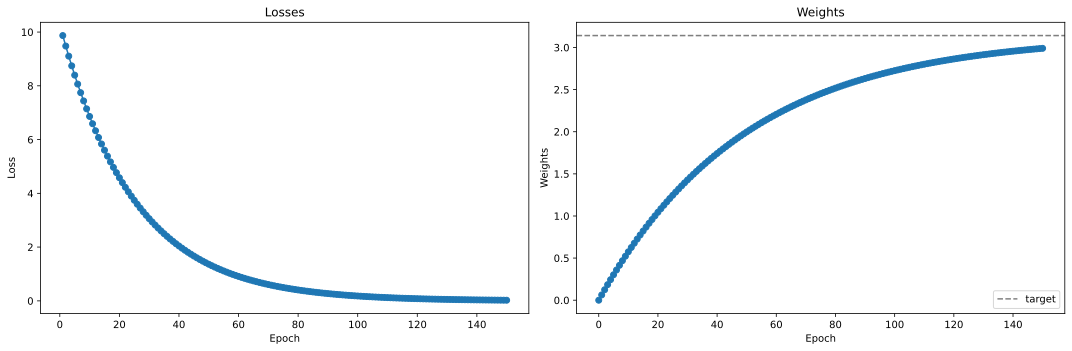

In [3]:
_, axs = plt.subplots(1,2,figsize=(15,5))

axs[0].plot(range(1,num_epochs+1), all_losses, '-o')
axs[0].set(title='Losses', xlabel = 'Epoch', ylabel='Loss')

axs[1].plot(range(0,num_epochs+1), all_weights, '-o')
axs[1].set(title='Weights', xlabel = 'Epoch', ylabel = 'Weights')

axs[1].axhline(target, linestyle='--', color = 'k', alpha = .5, label = 'target')

plt.legend()
plt.tight_layout()
plt.show()

## Optimizers Experiment

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

In [28]:
w_sgd   = torch.tensor([2.], requires_grad = True)
w_adam  = torch.tensor([2.], requires_grad = True)
w_adamW = torch.tensor([2.], requires_grad = True)

target = torch.tensor([5.])

num_epochs = 150

lr_sgd  = .04
lr_adam = .1

optimizer_sgd   = torch.optim.SGD([w_sgd],     lr = lr_sgd)
optimizer_adam  = torch.optim.Adam([w_adam],   lr = lr_adam)
optimizer_adamW = torch.optim.AdamW([w_adamW], lr = lr_adam)

all_losses  = torch.zeros(num_epochs, 3)
all_weights = torch.zeros(num_epochs+1, 3)
all_weights[0,:] = torch.tensor([w_sgd, w_adam, w_adamW])

for epoch in range(num_epochs):

  optimizer_sgd.zero_grad()
  loss_sgd = (w_sgd - target)**2
  loss_sgd.backward()
  optimizer_sgd.step()

  optimizer_adam.zero_grad()
  loss_adam = (w_adam - target)**2
  loss_adam.backward()
  optimizer_adam.step()

  optimizer_adamW.zero_grad()
  loss_adamW = (w_adamW - target)**2
  loss_adamW.backward()
  optimizer_adamW.step()



  all_losses[epoch, :] = torch.tensor([loss_sgd.item(),
                                       loss_adam.item(),
                                       loss_adamW.item()])

  all_weights[epoch+1, :] = torch.tensor([w_sgd.item(),
                                          w_adam.item(),
                                          w_adamW.item()])

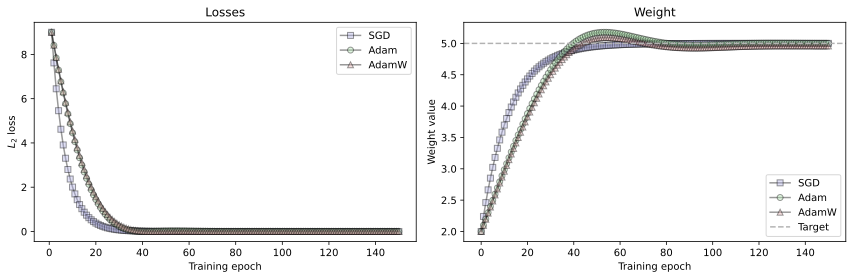

In [42]:
_, axs = plt.subplots(1, 2, figsize=(12, 4))

optim_labels = ['SGD', 'Adam', 'AdamW']

marker_cols = [
    [.7, .7, .9],
    [.7, .9, .7],
    [.9, .7, .7]
]

shapes = ['s', 'o', '^']

for i in range(3):

    axs[0].plot(range(1, num_epochs + 1),
                all_losses[:, i],
                color='k',
                marker=shapes[i],
                markerfacecolor=marker_cols[i],
                label=optim_labels[i],
                alpha=.4)

    axs[1].plot(range(0, num_epochs + 1),
                all_weights[:, i],
                color='k',
                marker=shapes[i],
                markerfacecolor=marker_cols[i],
                label=optim_labels[i],
                alpha=.4)

axs[0].set(title='Losses',
            ylabel='$L_2$ loss',
            xlabel='Training epoch')

axs[1].set(title='Weight',
          ylabel='Weight value',
          xlabel='Training epoch')

axs[1].axhline(target.item(),
              linestyle='--',
              color=[.7, .7, .7],
              label='Target')

for ax in axs:
    ax.legend()

plt.tight_layout()
plt.show()

Adam optimizers overshoots, it has small memory, so it keeps updating weights for couple of steps after reaching the lowest loss. SGD remembers only last step so it doesn't overshoot and reacts immediately.